<a href="https://colab.research.google.com/github/akshu88/Applied-ML-Lab/blob/main/Exp_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Iris Classification - comparing a few models

Quick notebook to try out a bunch of classifiers on the iris dataset and see which one does best. Nothing fancy, just the usual steps: load data, clean it up a bit, look at it, split it, train, check accuracy.

Models used: Logistic Regression, Decision Tree, Random Forest, KNN, SVM

**Step 0: Install & Import Libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_style('darkgrid')


## 1. Load the data

Upload `IRIS.csv` when the file picker pops up.

In [ ]:
from google.colab import files
uploaded = files.upload()

df = pd.read_csv('IRIS.csv')
df.head()


Saving IRIS.csv to IRIS.csv


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


## 2. Quick preprocessing

Just checking for nulls/dupes and encoding the species column since sklearn models want numbers not strings.

In [ ]:
print(df.shape)
print(df.isnull().sum())
print('duplicates:', df.duplicated().sum())

# not dropping duplicates here, iris naturally has a few identical rows and it's fine


(150, 5)
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64
duplicates: 3


In [ ]:
le = LabelEncoder()
df['species_enc'] = le.fit_transform(df['species'])

# just so i remember which number is which species
print(dict(zip(le.classes_, le.transform(le.classes_))))


{'Iris-setosa': np.int64(0), 'Iris-versicolor': np.int64(1), 'Iris-virginica': np.int64(2)}


(skipping feature selection / feature engineering - just using all 4 columns as they are)

## 3. Look at the data

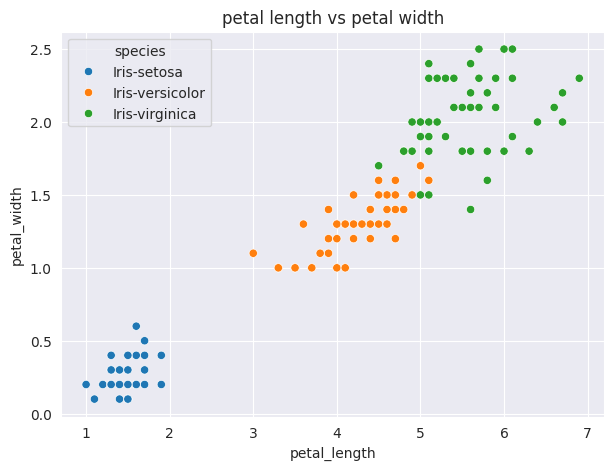

In [ ]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x='petal_length', y='petal_width', hue='species')
plt.title('petal length vs petal width')
plt.show()


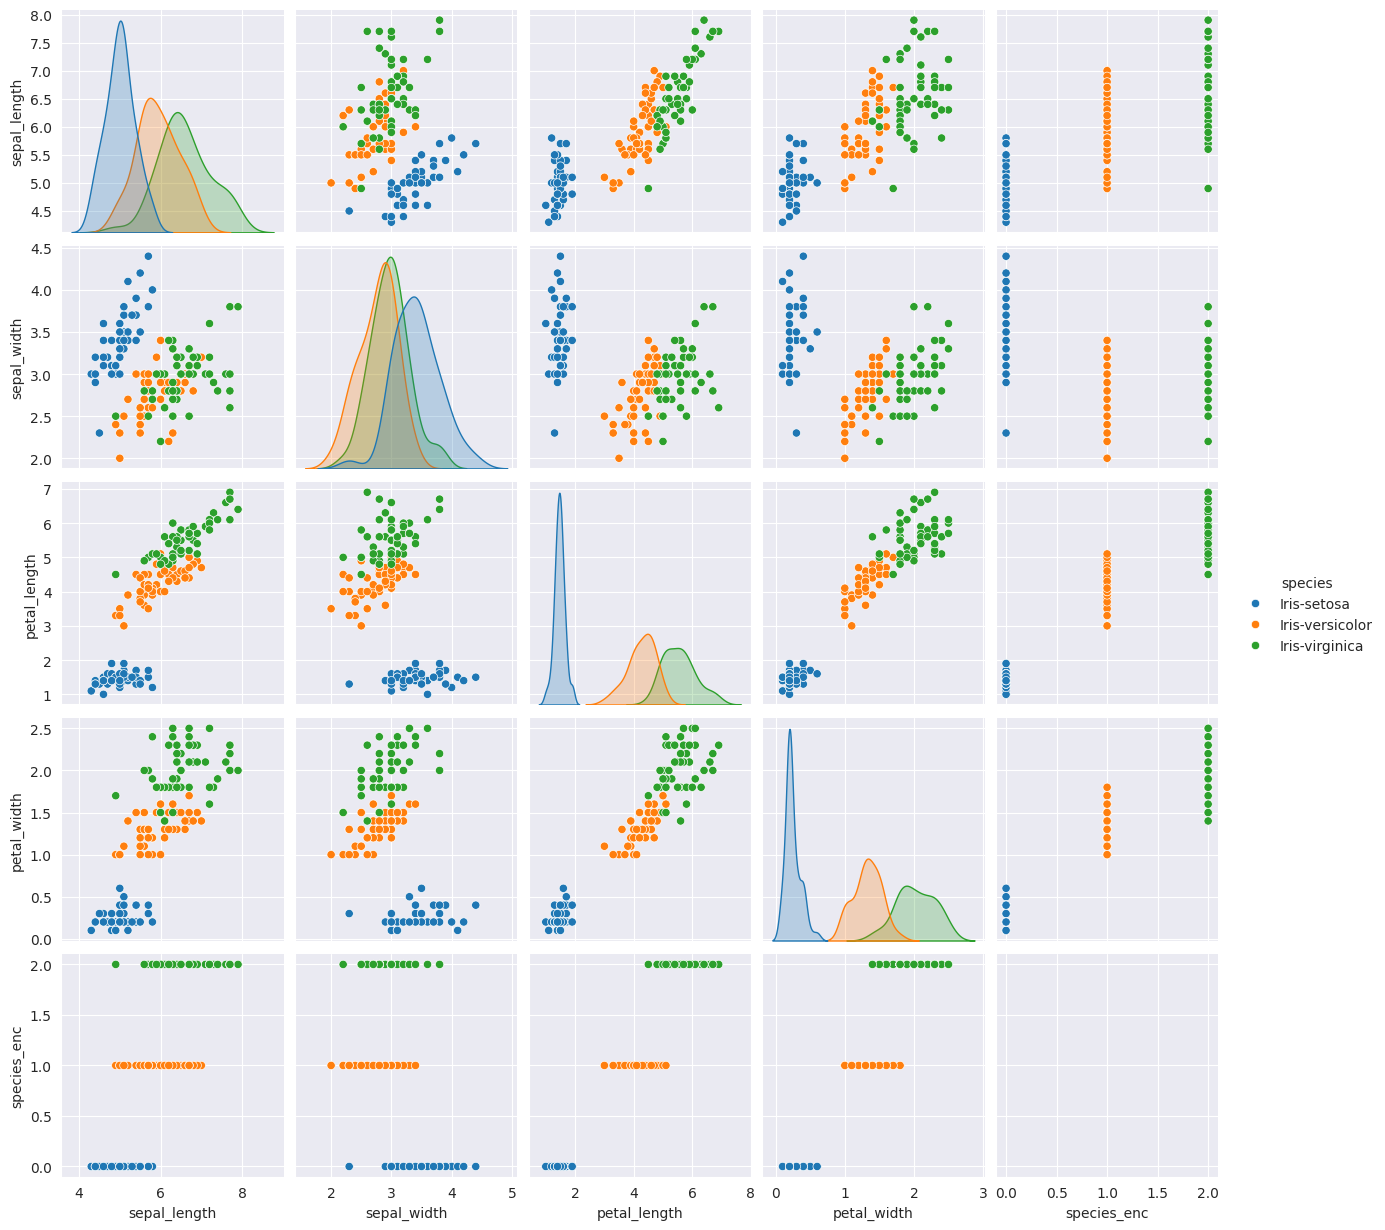

In [ ]:
sns.pairplot(df, hue='species')
plt.show()


## 4. Train/test split

In [ ]:
X = df[['sepal_length','sepal_width','petal_length','petal_width']]
y = df['species_enc']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# scaling helps KNN and SVM especially, doesn't hurt the tree-based ones
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train.shape, X_test.shape


((120, 4), (30, 4))

## 5. Logistic Regression

Starting with logistic regression since it's the closest thing here to "linear" - it still has coefficients and an intercept like a regression line, just squashed through a sigmoid to get class probabilities.

In [ ]:
log_reg = LogisticRegression(max_iter=200)
log_reg.fit(X_train_scaled, y_train)

log_pred = log_reg.predict(X_test_scaled)
log_acc = accuracy_score(y_test, log_pred)
print('accuracy:', log_acc)


accuracy: 0.9333333333333333


In [ ]:
# coefficients (one row per class since this is multiclass, one-vs-rest style)
print('coefficients (slope-equivalent):')
coef_df = pd.DataFrame(log_reg.coef_, columns=X.columns, index=le.classes_)
print(coef_df)

print('\nintercepts:')
print(dict(zip(le.classes_, log_reg.intercept_)))


coefficients (slope-equivalent):
                 sepal_length  sepal_width  petal_length  petal_width
Iris-setosa         -1.091782     1.020342     -1.797617    -1.695241
Iris-versicolor      0.538893    -0.359539     -0.207911    -0.800662
Iris-virginica       0.552890    -0.660802      2.005529     2.495903

intercepts:
{'Iris-setosa': np.float64(-0.3127251074650068), 'Iris-versicolor': np.float64(1.9105150026871198), 'Iris-virginica': np.float64(-1.5977898952221108)}


                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



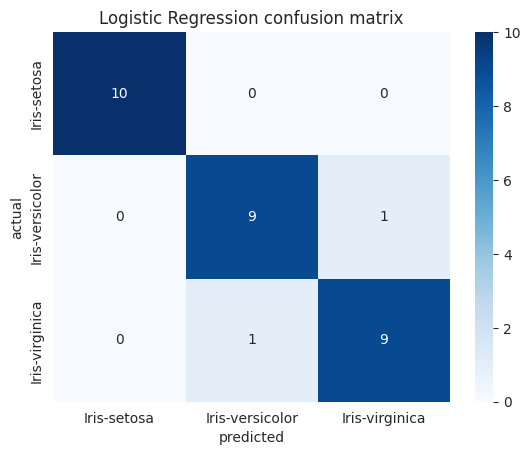

In [ ]:
print(classification_report(y_test, log_pred, target_names=le.classes_))
cm = confusion_matrix(y_test, log_pred)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=le.classes_, yticklabels=le.classes_, cmap='Blues')
plt.title('Logistic Regression confusion matrix')
plt.xlabel('predicted')
plt.ylabel('actual')
plt.show()


### "regression line" for logistic regression

Since logistic regression doesn't really have a straight line for 3 classes across 4 dimensions, the closest visual equivalent is a decision boundary. Doing this on just petal_length vs petal_width (the two most useful features) so it can actually be plotted in 2D.

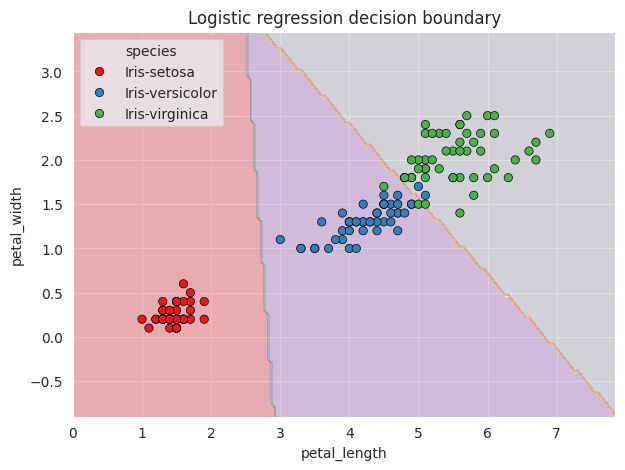

In [ ]:
# retrain just on the 2 features so we can draw a 2D boundary
X2 = df[['petal_length','petal_width']].values
y2 = df['species_enc'].values
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=42, stratify=y2)

log_reg_2d = LogisticRegression(max_iter=200)
log_reg_2d.fit(X2_train, y2_train)

x_min, x_max = X2[:,0].min()-1, X2[:,0].max()+1
y_min, y_max = X2[:,1].min()-1, X2[:,1].max()+1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05), np.arange(y_min, y_max, 0.05))
Z = log_reg_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(7,5))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='Set1')
sns.scatterplot(x=X2[:,0], y=X2[:,1], hue=df['species'], palette='Set1', edgecolor='k')
plt.xlabel('petal_length')
plt.ylabel('petal_width')
plt.title('Logistic regression decision boundary')
plt.show()


## 6. Decision Tree

In [ ]:
tree_clf = DecisionTreeClassifier(random_state=42)
tree_clf.fit(X_train, y_train)  # trees don't need scaling

tree_pred = tree_clf.predict(X_test)
tree_acc = accuracy_score(y_test, tree_pred)
print('accuracy:', tree_acc)
print(classification_report(y_test, tree_pred, target_names=le.classes_))


accuracy: 0.9333333333333333
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



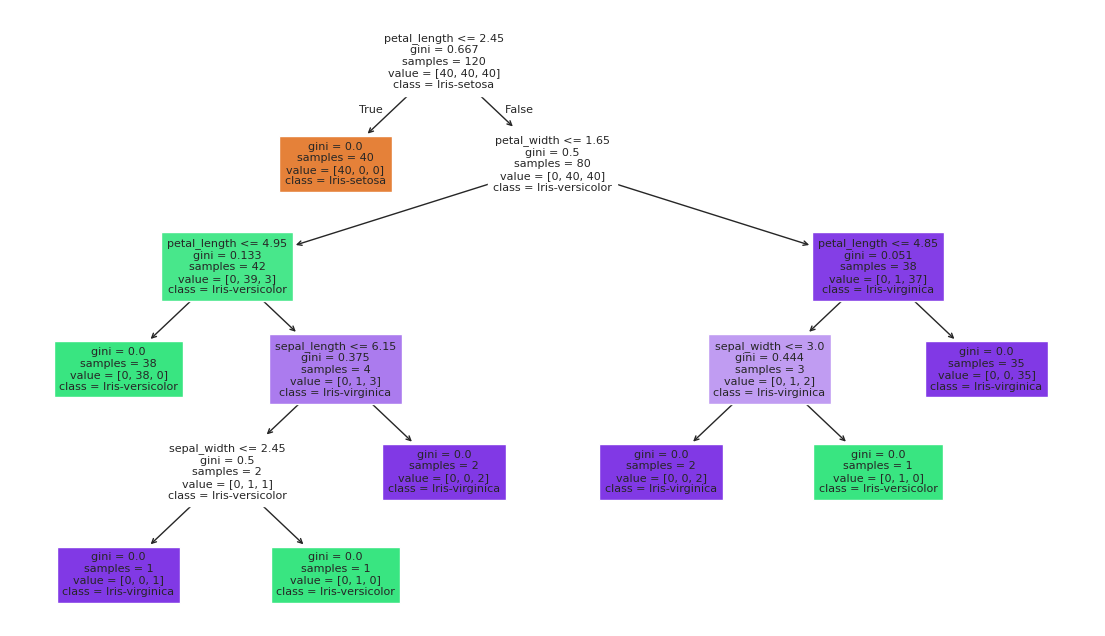

In [ ]:
from sklearn.tree import plot_tree
plt.figure(figsize=(14,8))
plot_tree(tree_clf, feature_names=X.columns, class_names=le.classes_, filled=True, fontsize=8)
plt.show()


## 7. Random Forest

In [ ]:
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(X_train, y_train)

rf_pred = rf_clf.predict(X_test)
rf_acc = accuracy_score(y_test, rf_pred)
print('accuracy:', rf_acc)
print(classification_report(y_test, rf_pred, target_names=le.classes_))


accuracy: 0.9
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.82      0.90      0.86        10
 Iris-virginica       0.89      0.80      0.84        10

       accuracy                           0.90        30
      macro avg       0.90      0.90      0.90        30
   weighted avg       0.90      0.90      0.90        30



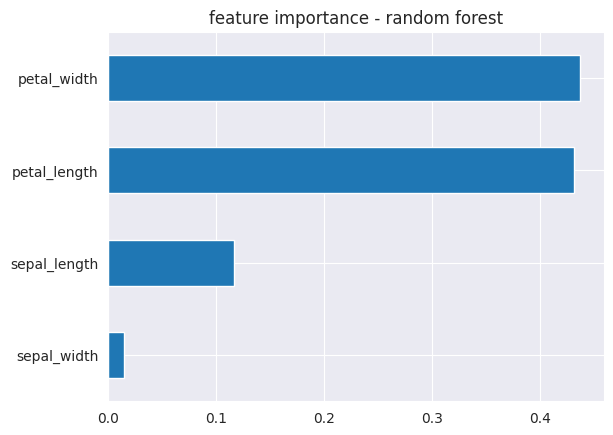

In [ ]:
# feature importance is kind of nice to look at with random forest
importances = pd.Series(rf_clf.feature_importances_, index=X.columns).sort_values()
importances.plot(kind='barh')
plt.title('feature importance - random forest')
plt.show()


## 8. K Nearest Neighbours

In [ ]:
knn_clf = KNeighborsClassifier(n_neighbors=5)
knn_clf.fit(X_train_scaled, y_train)  # scaled data, KNN cares about distance

knn_pred = knn_clf.predict(X_test_scaled)
knn_acc = accuracy_score(y_test, knn_pred)
print('accuracy:', knn_acc)
print(classification_report(y_test, knn_pred, target_names=le.classes_))


accuracy: 0.9333333333333333
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.83      1.00      0.91        10
 Iris-virginica       1.00      0.80      0.89        10

       accuracy                           0.93        30
      macro avg       0.94      0.93      0.93        30
   weighted avg       0.94      0.93      0.93        30



## 9. SVM (SVC)

In [ ]:
svm_clf = SVC(kernel='rbf')
svm_clf.fit(X_train_scaled, y_train)

svm_pred = svm_clf.predict(X_test_scaled)
svm_acc = accuracy_score(y_test, svm_pred)
print('accuracy:', svm_acc)
print(classification_report(y_test, svm_pred, target_names=le.classes_))


accuracy: 0.9666666666666667
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



## 10. Comparing all the models

In [ ]:
results = pd.DataFrame({
    'model': ['Logistic Regression', 'Decision Tree', 'Random Forest', 'KNN', 'SVM'],
    'accuracy': [log_acc, tree_acc, rf_acc, knn_acc, svm_acc]
}).sort_values('accuracy', ascending=False)

results


,model,accuracy
4,SVM,0.966667
0,Logistic Regression,0.933333
1,Decision Tree,0.933333
3,KNN,0.933333
2,Random Forest,0.900000


/tmp/ipykernel_6498/3873295787.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results, x='accuracy', y='model', palette='viridis')


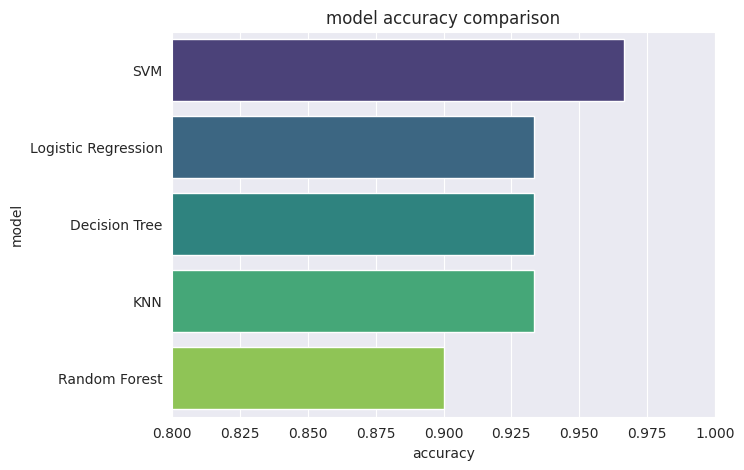

In [ ]:
plt.figure(figsize=(7,5))
sns.barplot(data=results, x='accuracy', y='model', palette='viridis')
plt.xlim(0.8, 1.0)
plt.title('model accuracy comparison')
plt.show()


## 11. Classifying a new flower

Quick function to run a new sample through whichever model you want.

In [ ]:
def classify_new_sample(sepal_length, sepal_width, petal_length, petal_width, model='rf'):
    sample = pd.DataFrame([[sepal_length, sepal_width, petal_length, petal_width]], columns=X.columns)
    sample_scaled = scaler.transform(sample)

    if model == 'log':
        pred = log_reg.predict(sample_scaled)[0]
    elif model == 'tree':
        pred = tree_clf.predict(sample)[0]
    elif model == 'rf':
        pred = rf_clf.predict(sample)[0]
    elif model == 'knn':
        pred = knn_clf.predict(sample_scaled)[0]
    elif model == 'svm':
        pred = svm_clf.predict(sample_scaled)[0]
    else:
        raise ValueError('model should be one of: log, tree, rf, knn, svm')

    return le.inverse_transform([pred])[0]

# try it out
print(classify_new_sample(5.9, 3.0, 5.1, 1.8, model='rf'))
print(classify_new_sample(5.1, 3.5, 1.4, 0.2, model='svm'))


Iris-virginica
Iris-setosa


---
Random forest and SVM usually come out on top for this dataset, logistic regression isn't far behind either since iris is pretty linearly separable anyway. Decision tree alone tends to be the weakest since it's more prone to overfitting without any pruning/depth limit.